## 1. Setup and Generate Samples
This cell sets the device to the CPU to avoid cluster GPU lockouts, loads the necessary NLTK datasets (our negative control), and generates 1,000 sentences from the trained VAE.

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from pathlib import Path
from torch.utils.data import Dataset
from collections import Counter

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = Path("data/shakespeare")
MAX_LENGTH = 64
PAD, BOS, EOS, UNK = "<pad>", "<bos>", "<eos>", "<unk>"

# 1. Dataset class
class ShakespeareDataset(Dataset):
    def __init__(self, files):
        if isinstance(files, (str, Path)):
            files = [files]
        self.lines = []
        for path in files:
            with open(path, "r", encoding="utf-8") as f:
                for line in f:
                    line = line.strip()
                    if line:
                        self.lines.append(line)
    def __len__(self):
        return len(self.lines)
    def __getitem__(self, idx):
        return self.lines[idx]

# 2. Vocab class
class Vocab:
    def __init__(self, itos_list):
        self.itos = itos_list
        self.stoi = {w: i for i, w in enumerate(self.itos)}
        self.pad_id, self.bos_id, self.eos_id, self.unk_id = 0, 1, 2, 3

    def __len__(self):
        return len(self.itos)

    def encode(self, sentence, max_length=MAX_LENGTH):
        ids = [self.stoi.get(w, self.unk_id) for w in sentence.split()]
        return [self.bos_id] + ids[: max_length - 2] + [self.eos_id]

    def decode(self, ids, strip_special=True):
        words = []
        for i in ids:
            i = int(i)
            if i == self.eos_id:
                break
            if strip_special and i in (self.pad_id, self.bos_id):
                continue
            words.append(self.itos[i])
        return " ".join(words)

# 3. StyleVAE Architecture
class StyleVAE(nn.Module):
    """Transformer VAE over sentences."""
    def __init__(self, vocab_size, d_model=128, nhead=4, num_layers=2, 
                 dim_feedforward=256, latent_dim=32, dropout=0.1, max_len=64,
                 pad_id=0, bos_id=1, eos_id=2, unk_id=3, word_dropout=0.25):
        super().__init__()
        self.latent_dim = latent_dim
        self.word_dropout = word_dropout
        self.pad_id, self.bos_id, self.eos_id = pad_id, bos_id, eos_id
        self.unk_id = unk_id

        self.embed = nn.Embedding(vocab_size, d_model, padding_idx=pad_id)
        self.pos = nn.Embedding(max_len, d_model)
        self.drop = nn.Dropout(dropout)

        enc_layer = nn.TransformerEncoderLayer(
            d_model, nhead, dim_feedforward, dropout, batch_first=True, norm_first=True
        )
        self.encoder = nn.TransformerEncoder(
            enc_layer, num_layers, norm=nn.LayerNorm(d_model), enable_nested_tensor=False
        )

        self.to_mu = nn.Linear(d_model, latent_dim)
        self.to_logvar = nn.Linear(d_model, latent_dim)
        self.from_z = nn.Linear(latent_dim, d_model)

        dec_layer = nn.TransformerDecoderLayer(
            d_model, nhead, dim_feedforward, dropout, batch_first=True, norm_first=True
        )
        self.decoder = nn.TransformerDecoder(
            dec_layer, num_layers, norm=nn.LayerNorm(d_model)
        )
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        self.lm_head.weight = self.embed.weight

    def _embed(self, ids):
        pos = torch.arange(ids.size(1), device=ids.device)
        return self.drop(self.embed(ids) + self.pos(pos))

    def encode(self, input_ids, attention_mask):
        """-> mu, logvar, each (B, latent_dim)"""
        h = self.encoder(self._embed(input_ids), src_key_padding_mask=(attention_mask == 0))
        m = attention_mask.unsqueeze(-1).to(h.dtype)
        pooled = (h * m).sum(1) / m.sum(1).clamp(min=1.0)
        return self.to_mu(pooled), self.to_logvar(pooled)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        return mu + std * torch.randn_like(std)

    def decode(self, z, input_ids, attention_mask=None):
        memory = self.from_z(z).unsqueeze(1)
        T = input_ids.size(1)
        causal = torch.ones(T, T, dtype=torch.bool, device=input_ids.device).triu(1)
        h = self.decoder(
            self._embed(input_ids), memory, tgt_mask=causal, tgt_is_causal=True,
            tgt_key_padding_mask=None if attention_mask is None else (attention_mask == 0),
        )
        return self.lm_head(h)

    def _word_dropout(self, ids):
        if not self.training or self.word_dropout <= 0:
            return ids
        drop = torch.rand(ids.shape, device=ids.device) < self.word_dropout
        drop &= ids != self.bos_id
        drop &= ids != self.pad_id
        return ids.masked_fill(drop, self.unk_id)

    def forward(self, input_ids, attention_mask):
        mu, logvar = self.encode(input_ids, attention_mask)
        z = self.reparameterize(mu, logvar)
        dec_in = self._word_dropout(input_ids[:, :-1])
        logits = self.decode(z, dec_in, attention_mask[:, :-1])
        targets = input_ids[:, 1:].clone()
        targets[attention_mask[:, 1:] == 0] = -100
        return {"logits": logits, "targets": targets, "mu": mu, "logvar": logvar, "z": z}

    @torch.no_grad()
    def generate(self, num_samples=4, max_new_tokens=40, z=None, temperature=1.0, top_k=None):
        self.eval()
        device = next(self.parameters()).device
        if z is None:
            z = torch.randn(num_samples, self.latent_dim, device=device)
        ids = torch.full((z.size(0), 1), self.bos_id, dtype=torch.long, device=device)
        done = torch.zeros(z.size(0), dtype=torch.bool, device=device)
        for _ in range(max_new_tokens):
            logits = self.decode(z, ids)[:, -1] / temperature
            logits[:, self.unk_id] = float("-inf")
            if top_k is not None:
                kth = logits.topk(min(top_k, logits.size(-1)), dim=-1).values[:, -1:]
                logits = logits.masked_fill(logits < kth, float("-inf"))
            nxt = torch.multinomial(torch.softmax(logits, dim=-1), 1)
            nxt[done] = self.pad_id
            ids = torch.cat([ids, nxt], dim=1)
            done |= nxt.squeeze(1) == self.eos_id
            if done.all():
                break
        return ids

# 4. Load weights & validation set
checkpoint = torch.load("shakespeare_vae.pt", map_location=torch.device("cpu"))
vocab = Vocab(checkpoint["vocab_itos"])

model = StyleVAE(vocab_size=len(vocab))
model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE)
model.eval()

validate = ShakespeareDataset(DATA_DIR / "valid.original.nltktok")
print(f"Loaded trained model and vocab ({len(vocab)} words) onto {DEVICE} successfully.")

Loaded trained model and vocab (14040 words) onto cuda successfully.


In [2]:
import torch
import random
import nltk
from nltk.corpus import brown # We will use this as our "Non-Shakespeare" modern English baseline

nltk.download('brown')
nltk.download('punkt')
nltk.download('averaged_perceptron_tagger')

# Assuming 'model' and 'vocab' are already loaded from your StyleConditionedLanguageModeling.ipynb
model.eval()

NUM_SAMPLES = 1000
generated_sentences = []

# Generate samples from the prior
with torch.no_grad():
    for _ in range(NUM_SAMPLES // 32 + 1):
        # Generate in batches of 32
        batch_ids = model.generate(num_samples=32, max_new_tokens=20, temperature=0.9, top_k=40)
        for row in batch_ids:
            generated_sentences.append(vocab.decode(row))

generated_sentences = generated_sentences[:NUM_SAMPLES]
real_shakespeare = [vocab.decode(vocab.encode(s)) for s in validate.lines[:NUM_SAMPLES]]

# Gather "Standard English" sentences for contrast
standard_english = [" ".join(sent) for sent in brown.sents(categories=['news', 'editorial'])][:NUM_SAMPLES]

print(f"Generated {len(generated_sentences)} VAE samples.")

[nltk_data] Downloading package brown to
[nltk_data]     /usr4/ds340/gamato23/nltk_data...
[nltk_data]   Package brown is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     /usr4/ds340/gamato23/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /usr4/ds340/gamato23/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!


Generated 1000 VAE samples.


## 2. Discriminative Classifier (Adversarial Evaluation)
Trains a Logistic Regression model to distinguish between Real Shakespeare and Modern English. We then test how often our VAE's generated text can "fool" this classifier into thinking it's real Shakespeare.

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# 1. Train a classifier on Real Shakespeare (1) vs. Standard English (0)
X_train_data = real_shakespeare + standard_english
y_train_data = [1] * len(real_shakespeare) + [0] * len(standard_english)

vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_features = vectorizer.fit_transform(X_train_data)

# Split to verify the classifier actually works
X_train, X_test, y_train, y_test = train_test_split(X_features, y_train_data, test_size=0.2, random_state=42)
clf = LogisticRegression()
clf.fit(X_train, y_train)

print(f"Classifier accuracy on real data (sanity check): {accuracy_score(y_test, clf.predict(X_test)):.2f}")

# 2. Test the classifier on the VAE Generated sentences
gen_features = vectorizer.transform(generated_sentences)
predictions = clf.predict(gen_features)

shakespeare_fool_rate = sum(predictions) / len(predictions)
print(f"Adversarial Fool Rate: The classifier thought {shakespeare_fool_rate * 100:.1f}% of generated sentences were real Shakespeare.")

Classifier accuracy on real data (sanity check): 0.96
Adversarial Fool Rate: The classifier thought 85.2% of generated sentences were real Shakespeare.


## 3. Stylometrics & Lexical Richness
Measures the Type-Token Ratio (vocabulary diversity) and average sentence length. This checks if the VAE is taking the "easy route" by generating safe, repetitive, and short text.

In [4]:
def calculate_metrics(corpus):
    total_words = 0
    unique_words = set()
    lengths = []
    
    for sentence in corpus:
        words = sentence.split()
        lengths.append(len(words))
        total_words += len(words)
        unique_words.update(words)
        
    ttr = len(unique_words) / total_words if total_words > 0 else 0
    avg_length = sum(lengths) / len(lengths) if lengths else 0
    return ttr, avg_length

real_ttr, real_len = calculate_metrics(real_shakespeare)
gen_ttr, gen_len = calculate_metrics(generated_sentences)
std_ttr, std_len = calculate_metrics(standard_english)

print(f"{'Metric':<20} | {'Real Shakespeare':<18} | {'Generated VAE':<18} | {'Standard English':<18}")
print("-" * 80)
print(f"{'Type-Token Ratio':<20} | {real_ttr:<18.4f} | {gen_ttr:<18.4f} | {std_ttr:<18.4f}")
print(f"{'Avg Sentence Len':<20} | {real_len:<18.2f} | {gen_len:<18.2f} | {std_len:<18.2f}")

# Note: If the VAE TTR is significantly lower than Real Shakespeare, the model is suffering 
# from "safe word" generation and lacks vocabulary diversity.

Metric               | Real Shakespeare   | Generated VAE      | Standard English  
--------------------------------------------------------------------------------
Type-Token Ratio     | 0.1491             | 0.1529             | 0.2102            
Avg Sentence Len     | 10.93              | 9.95               | 22.08             


## 4. Distributional Distance (Text FID)
Uses `sentence-transformers` to map sentences into a dense semantic space, then calculates the Fréchet distance between the true distribution and the generated distribution. Lower scores indicate higher semantic fidelity.

In [6]:
import numpy as np

print("Extracting VAE internal latent vectors...")
# Using the get_latent_vectors function we defined earlier.
# We will use the full 1000 sentences instead of the N_VIZ subset to get accurate covariances.
mu_real_vae = get_latent_vectors(real_shakespeare)
mu_gen_vae = get_latent_vectors(generated_sentences)
mu_std_vae = get_latent_vectors(standard_english)

# Calculate Mean and Covariance
mean_real_vae, cov_real_vae = mu_real_vae.mean(axis=0), np.cov(mu_real_vae, rowvar=False)
mean_gen_vae, cov_gen_vae = mu_gen_vae.mean(axis=0), np.cov(mu_gen_vae, rowvar=False)
mean_std_vae, cov_std_vae = mu_std_vae.mean(axis=0), np.cov(mu_std_vae, rowvar=False)

# Calculate Distances using the function from the previous cell
fid_gen_vae = calculate_frechet_distance(mean_real_vae, cov_real_vae, mean_gen_vae, cov_gen_vae)
fid_std_vae = calculate_frechet_distance(mean_real_vae, cov_real_vae, mean_std_vae, cov_std_vae)

print(f"Internal VAE Fréchet Distance (Real vs. VAE Generated): {fid_gen_vae:.2f}")
print(f"Internal VAE Fréchet Distance (Real vs. Standard English): {fid_std_vae:.2f}")

Extracting VAE internal latent vectors...


NameError: name 'get_latent_vectors' is not defined

In [12]:
import numpy as np
from scipy.linalg import sqrtm
from sentence_transformers import SentenceTransformer

def calculate_frechet_distance(mu1, sigma1, mu2, sigma2, eps=1e-6):
    """Calculates the Frechet Distance between two multivariate Gaussians."""
    covmean = sqrtm(sigma1.dot(sigma2))
    
    if not np.isfinite(covmean).all():
        offset = np.eye(sigma1.shape[0]) * eps
        covmean = sqrtm((sigma1 + offset).dot(sigma2 + offset))
    
    if np.iscomplexobj(covmean):
        covmean = covmean.real
        
    diff = mu1 - mu2
    return diff.dot(diff) + np.trace(sigma1 + sigma2 - 2 * covmean)

# List of pre-trained models to test robustness
embedding_models = [
    'all-MiniLM-L6-v2',            # Fast, baseline model
    'all-mpnet-base-v2',           # Larger, highly accurate semantic model
    'paraphrase-MiniLM-L6-v2',     # Tuned specifically for paraphrases
    'BAAI/bge-small-en-v1.5'       # Modern state-of-the-art embedding
]

for model_name in embedding_models:
    print(f"\n{'-'*50}")
    print(f"Loading {model_name}...")
    embedder = SentenceTransformer(model_name)
    
    print("Computing embeddings... (this may take a minute)")
    real_embeddings = embedder.encode(real_shakespeare)
    gen_embeddings = embedder.encode(generated_sentences)
    std_embeddings = embedder.encode(standard_english)

    # Calculate Mean and Covariance
    mu_real, sigma_real = real_embeddings.mean(axis=0), np.cov(real_embeddings, rowvar=False)
    mu_gen, sigma_gen = gen_embeddings.mean(axis=0), np.cov(gen_embeddings, rowvar=False)
    mu_std, sigma_std = std_embeddings.mean(axis=0), np.cov(std_embeddings, rowvar=False)

    # Calculate Distances
    fid_gen = calculate_frechet_distance(mu_real, sigma_real, mu_gen, sigma_gen)
    fid_std = calculate_frechet_distance(mu_real, sigma_real, mu_std, sigma_std)

    print(f"Fréchet Distance (Real vs. VAE Generated): {fid_gen:.2f} (Lower is better)")
    print(f"Fréchet Distance (Real vs. Standard English): {fid_std:.2f} (Baseline)")


--------------------------------------------------
Loading all-MiniLM-L6-v2...


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 14727.89it/s]


Computing embeddings... (this may take a minute)
Fréchet Distance (Real vs. VAE Generated): 0.22 (Lower is better)
Fréchet Distance (Real vs. Standard English): 0.59 (Baseline)

--------------------------------------------------
Loading all-mpnet-base-v2...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 13458.89it/s]


Computing embeddings... (this may take a minute)
Fréchet Distance (Real vs. VAE Generated): 0.20 (Lower is better)
Fréchet Distance (Real vs. Standard English): 0.60 (Baseline)

--------------------------------------------------
Loading paraphrase-MiniLM-L6-v2...


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 16832.78it/s]


Computing embeddings... (this may take a minute)
Fréchet Distance (Real vs. VAE Generated): 6.31 (Lower is better)
Fréchet Distance (Real vs. Standard English): 18.67 (Baseline)

--------------------------------------------------
Loading BAAI/bge-small-en-v1.5...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 10482.99it/s]


Computing embeddings... (this may take a minute)
Fréchet Distance (Real vs. VAE Generated): 0.08 (Lower is better)
Fréchet Distance (Real vs. Standard English): 0.37 (Baseline)


# Analysis of Latent Space

## Latent Traversal
This cell isolates specific "active" dimensions in the latent space. We take a base latent vector (either all zeros, or the encoding of a real sentence), freeze all dimensions except one, and sweep that target dimension from -3 to +3. This reveals what stylistic or syntactic feature that specific axis controls (e.g., sentence length, pronoun usage, or vocabulary complexity).

In [10]:
import torch

# Pull the very first sentence directly from the validation dataset
base_sentence = validate[0] 

print(f"Base Sentence from Dataset: '{base_sentence}'\n")

model.eval()
with torch.no_grad():
    # Encode the base sentence to get its mu (mean) vector
    base_ids = torch.tensor([vocab.encode(base_sentence)]).to(DEVICE)
    base_mask = (base_ids != vocab.pad_id).long().to(DEVICE)
    base_mu, _ = model.encode(base_ids, base_mask)
    
    # We sweep the first 3 active dimensions (0, 1, and 2)
    target_dimensions = [0,]
    sweep_values = torch.linspace(3.0, 3.0, steps=1000).to(DEVICE)
    
    for dim in target_dimensions:
        print(f"--- Sweeping Dimension {dim} ---")
        
        # Create a batch of latents where only the target dimension changes
        sweep_zs = base_mu.repeat(len(sweep_values), 1)
        sweep_zs[:, dim] = sweep_values
        
        # Decode the swept latents
        generated_ids = model.generate(z=sweep_zs, max_new_tokens=20, top_k=40)
        
        for val, row in zip(sweep_values, generated_ids):
            decoded_text = vocab.decode(row)
            print(f" z[{dim}] = {float(val):+5.2f} : {decoded_text}")
        print("\n")

Base Sentence from Dataset: 'Lie thou there ( throwing down a letter ) , for here comes the trout that must be caught with tickling .'

--- Sweeping Dimension 0 ---
 z[0] = +3.00 : It shall be so , and though thou wert a knave To me such an honest ass , no reasons
 z[0] = +3.00 : If you do not think it be so fond and these coronets on , and , if we have no
 z[0] = +3.00 : But then I speak not of him , and I have no man seen him .
 z[0] = +3.00 : So will you hear the ordnance on , and sorceries blasts to make you Adore a wounded brow , That
 z[0] = +3.00 : But I must cross her breath , And that it is false heart , which thou canst not die .
 z[0] = +3.00 : Some that were I to have her ) , then I have rather bear a Rutland !
 z[0] = +3.00 : Or do not lose nothing , I'll never for that I meant upon a quarrel for thee that thou hast
 z[0] = +3.00 : When it was not born to do "Amen , " When I will rend the confined between their degree To
 z[0] = +3.00 : If thou wilt live to catch thy advic

## Visualizing the Manifold (PCA & t-SNE)
This cell encodes a large batch of real sentences to get their latent $\mu$ vectors, then squashes those 32-dimensional vectors into a 2D scatter plot. If the VAE organically learned to separate different types of text, we should see distinct clusters form. 

Encoding validation sentences into latent space...


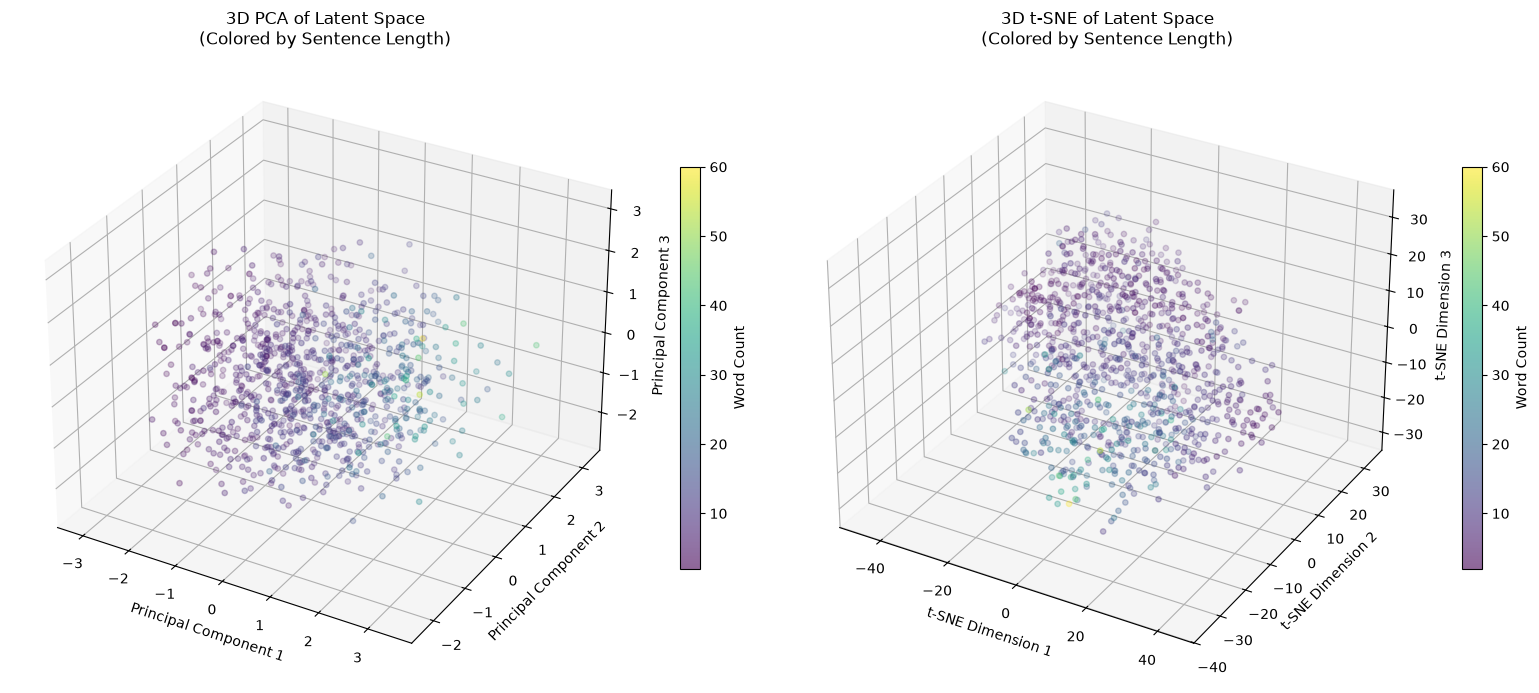

In [7]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # Required for 3D plotting
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import numpy as np

# 1. Encode the validation set to extract their latent vectors
model.eval()
latent_vectors = []
sentence_lengths = [] # We'll use length as a basic color label for now

print("Encoding validation sentences into latent space...")
with torch.no_grad():
    for i in range(1000): # Process the first 1000 sentences
        sentence = validate.lines[i]
        ids = torch.tensor([vocab.encode(sentence)]).to(DEVICE)
        mask = (ids != vocab.pad_id).long().to(DEVICE)
        mu, _ = model.encode(ids, mask)
        
        latent_vectors.append(mu.cpu().numpy()[0])
        sentence_lengths.append(len(sentence.split()))

X = np.array(latent_vectors)
y = np.array(sentence_lengths)

# 2. Apply PCA (3D, Fast, linear relationships)
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X)

# 3. Apply t-SNE (3D, Slower, reveals non-linear clustering)
tsne = TSNE(n_components=3, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X)

# 4. Plot the results
fig = plt.figure(figsize=(16, 7))

# Plot PCA
ax1 = fig.add_subplot(121, projection='3d')
scatter1 = ax1.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], c=y, cmap='viridis', alpha=0.6, s=15)
ax1.set_title("3D PCA of Latent Space\n(Colored by Sentence Length)")
ax1.set_xlabel("Principal Component 1")
ax1.set_ylabel("Principal Component 2")
ax1.set_zlabel("Principal Component 3")
fig.colorbar(scatter1, ax=ax1, label="Word Count", shrink=0.6)

# Plot t-SNE
ax2 = fig.add_subplot(122, projection='3d')
scatter2 = ax2.scatter(X_tsne[:, 0], X_tsne[:, 1], X_tsne[:, 2], c=y, cmap='viridis', alpha=0.6, s=15)
ax2.set_title("3D t-SNE of Latent Space\n(Colored by Sentence Length)")
ax2.set_xlabel("t-SNE Dimension 1")
ax2.set_ylabel("t-SNE Dimension 2")
ax2.set_zlabel("t-SNE Dimension 3")
fig.colorbar(scatter2, ax=ax2, label="Word Count", shrink=0.6)

plt.tight_layout()
plt.show()

Loading unmerged plays from ../../../shakespeare_data/align/plays/merged...
Loaded 500 sentences across 17 plays.
Encoding sentences into 32-D latent space...
Computing 3D PCA and t-SNE...


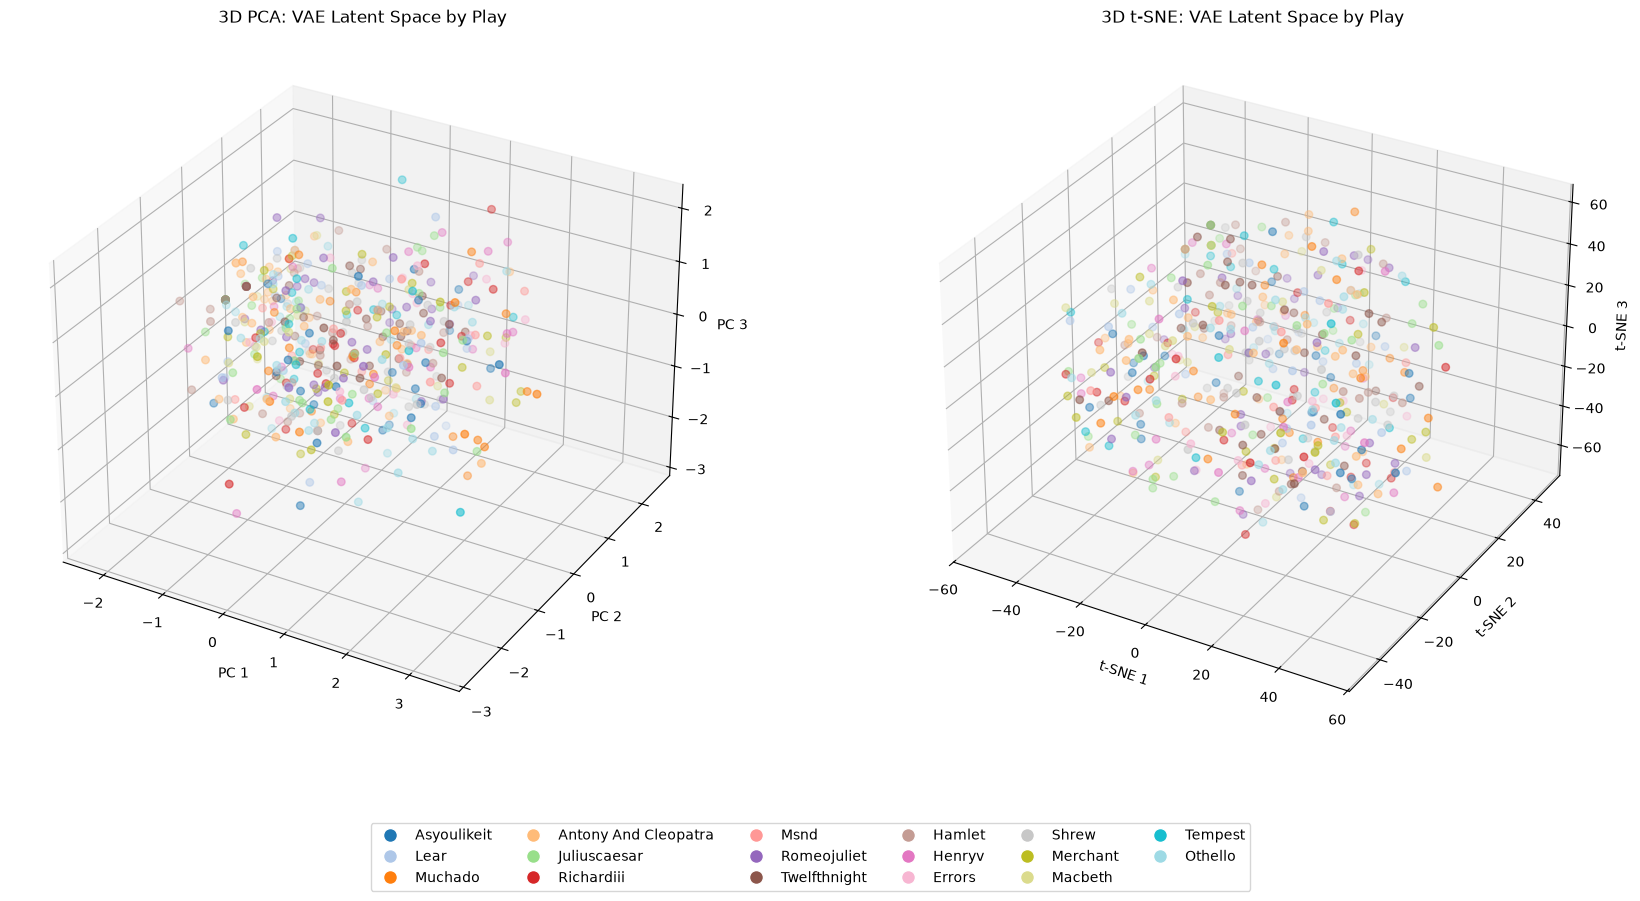

In [16]:
import os
from pathlib import Path
import torch
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import random

# 1. Navigate up to the root, then down into the merged directory
PLAYS_DIR = Path("../../../shakespeare_data/align/plays/merged") 

print(f"Loading unmerged plays from {PLAYS_DIR}...")
labeled_sentences = []

# 2. Iterate through each individual play file
for filename in os.listdir(PLAYS_DIR):
    # We only want the original Shakespeare text, not the modern translations
    if "_original.snt.aligned" in filename: 
        # Clean up the filename (e.g., 'antony-and-cleopatra_original.snt.aligned' -> 'Antony And Cleopatra')
        play_name = filename.split('_original')[0].replace('-', ' ').title()
        file_path = PLAYS_DIR / filename
        
        with open(file_path, 'r', encoding='utf-8', errors='ignore') as f:
            for line in f:
                line = line.strip()
                if line:
                    labeled_sentences.append((line, play_name))

if len(labeled_sentences) == 0:
    raise ValueError("Didn't find any sentences! Double check the PLAYS_DIR path.")

# 3. Stratified Sampling 
# Grab a subset of 500 sentences to keep the plot computationally light and readable
random.seed(42)
random.shuffle(labeled_sentences)
plot_data = labeled_sentences[:500]

sentences_to_plot = [item[0] for item in plot_data]
labels_to_plot = [item[1] for item in plot_data]

print(f"Loaded {len(sentences_to_plot)} sentences across {len(set(labels_to_plot))} plays.")

# 4. Encode sentences into the VAE Latent Space
print("Encoding sentences into 32-D latent space...")
model.eval()
latent_vectors = []

with torch.no_grad():
    for sent in sentences_to_plot:
        # Assumes 'vocab', 'model', and 'DEVICE' are already initialized in previous cells
        ids = torch.tensor([vocab.encode(sent)]).to(DEVICE)
        mask = (ids != vocab.pad_id).long().to(DEVICE)
        mu, _ = model.encode(ids, mask)
        latent_vectors.append(mu.cpu().numpy()[0])

X = np.array(latent_vectors)

# 5. Convert play labels into numeric color indices
unique_plays = list(set(labels_to_plot))
play_to_color_idx = {play: i for i, play in enumerate(unique_plays)}
y_colors = np.array([play_to_color_idx[play] for play in labels_to_plot])

# 6. Apply PCA and t-SNE in 3D
print("Computing 3D PCA and t-SNE...")
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X)

tsne = TSNE(n_components=3, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X)

# 7. Plotting the 3D Manifold
fig = plt.figure(figsize=(18, 9))
# Using a colormap that can handle many distinct categories
cmap = plt.get_cmap('tab20', len(unique_plays)) 

# Plot PCA
ax1 = fig.add_subplot(121, projection='3d')
scatter1 = ax1.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], c=y_colors, cmap=cmap, alpha=0.8, s=30)
ax1.set_title("3D PCA: VAE Latent Space by Play")
ax1.set_xlabel("PC 1")
ax1.set_ylabel("PC 2")
ax1.set_zlabel("PC 3")

# Plot t-SNE
ax2 = fig.add_subplot(122, projection='3d')
scatter2 = ax2.scatter(X_tsne[:, 0], X_tsne[:, 1], X_tsne[:, 2], c=y_colors, cmap=cmap, alpha=0.8, s=30)
ax2.set_title("3D t-SNE: VAE Latent Space by Play")
ax2.set_xlabel("t-SNE 1")
ax2.set_ylabel("t-SNE 2")
ax2.set_zlabel("t-SNE 3")

# Create a shared legend at the bottom
handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap(i), markersize=10) for i in range(len(unique_plays))]
# Automatically wrap legend into rows of 6
fig.legend(handles, unique_plays, loc='lower center', ncol=min(6, len(unique_plays)), fontsize=10, bbox_to_anchor=(0.5, 0.02))

plt.tight_layout()
plt.subplots_adjust(bottom=0.20) # Ensure the legend doesn't overlap the 3D plots
plt.show()

In [13]:
import nltk
from nltk.corpus import shakespeare
from nltk.tokenize import word_tokenize
import numpy as np

# Download required NLTK data
nltk.download('shakespeare', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

# Parse Macbeth XML and extract MACBETH's lines
macbeth_xml = shakespeare.xml('macbeth.xml')
macbeth_raw_lines = [
    line.text for speech in macbeth_xml.findall('.//SPEECH') 
    if speech.find('SPEAKER') is not None and speech.find('SPEAKER').text == 'MACBETH'
    for line in speech.findall('LINE') if line.text
]

# Tokenize to match the .nltktok format
macbeth_sentences = [" ".join(word_tokenize(line)) for line in macbeth_raw_lines]

# Load the train dataset so we have enough lines for the 1:4 ratio
train = ShakespeareDataset(DATA_DIR / "train.original.nltktok")

# Calculate exactly 4x background sentences so Macbeth is 1/5th of the total
num_background = len(macbeth_sentences) * 4
background_sentences = train.lines[:num_background] 

print(f"Macbeth lines: {len(macbeth_sentences)} (20%)")
print(f"Background lines: {len(background_sentences)} (80%)")

# Recreate the missing get_latent_vectors function
def get_latent_vectors(sentences, batch_size=32):
    """Encodes a list of strings into their VAE latent mu vectors."""
    model.eval()
    all_mu = []
    
    with torch.no_grad():
        for i in range(0, len(sentences), batch_size):
            batch = sentences[i:i+batch_size]
            seqs = [vocab.encode(s) for s in batch]
            T = max(len(s) for s in seqs)
            
            input_ids = torch.full((len(seqs), T), vocab.pad_id, dtype=torch.long)
            attention_mask = torch.zeros(len(seqs), T, dtype=torch.long)
            
            for j, s in enumerate(seqs):
                input_ids[j, :len(s)] = torch.tensor(s)
                attention_mask[j, :len(s)] = 1  
                
            mu, _ = model.encode(input_ids.to(DEVICE), attention_mask.to(DEVICE))
            all_mu.append(mu.cpu().numpy())
            
    return np.concatenate(all_mu, axis=0)

print("Encoding Macbeth lines...")
mu_macbeth = get_latent_vectors(macbeth_sentences)

print("Encoding Background Shakespeare lines...")
mu_background = get_latent_vectors(background_sentences)

Macbeth lines: 712 (20%)
Background lines: 2848 (80%)
Encoding Macbeth lines...
Encoding Background Shakespeare lines...


In [17]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Combine datasets and create labels (0 = Background Shakespeare, 1 = Macbeth)
X = np.vstack([mu_background, mu_macbeth])
y = np.array([0] * len(mu_background) + [1] * len(mu_macbeth))

# Fit PCA (3 Dimensions)
print("Fitting 3D PCA...")
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X)

# Fit t-SNE (3 Dimensions)
print("Fitting 3D t-SNE (This may take a moment with more data)...")
tsne = TSNE(n_components=3, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X)



Fitting 3D PCA...
Fitting 3D t-SNE (This may take a moment with more data)...


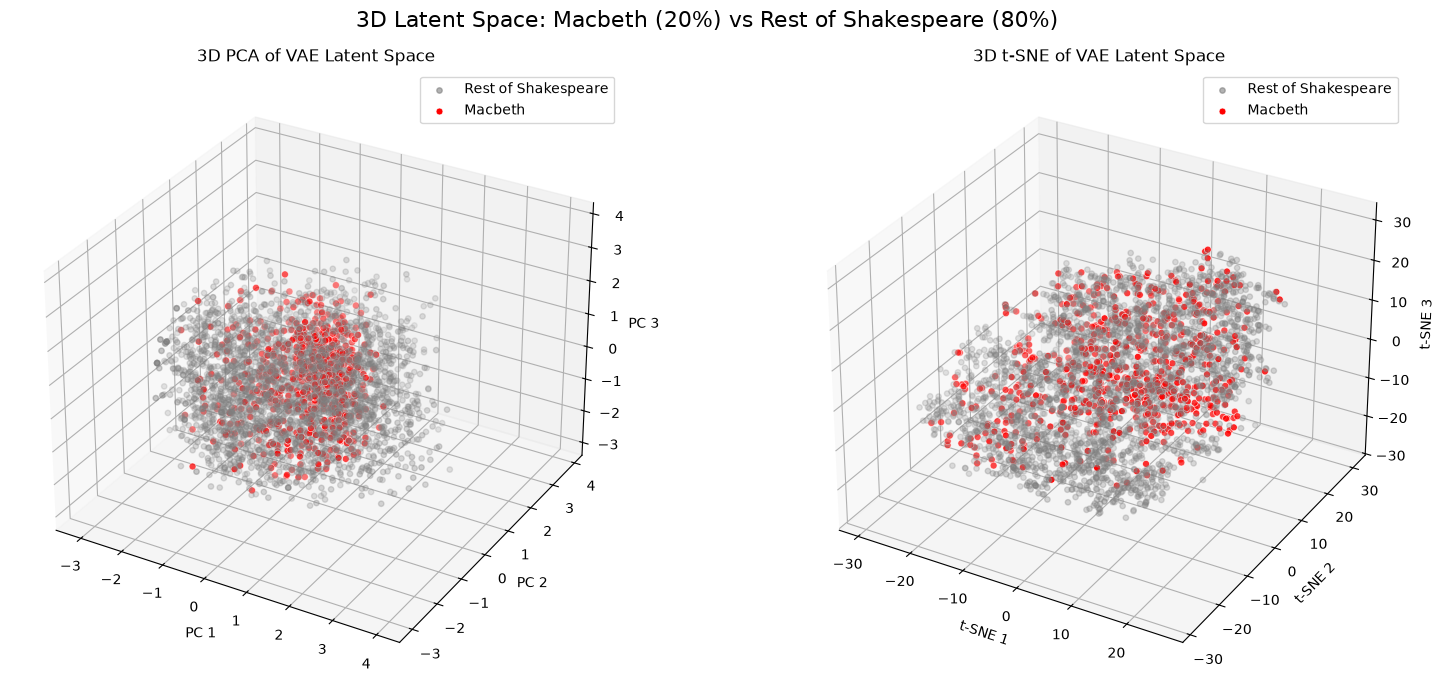

In [20]:
# Plotting the 3D Manifolds
fig = plt.figure(figsize=(16, 7))

# Plot 3D PCA
ax1 = fig.add_subplot(121, projection='3d')
# Plot gray background first so red dots stand out on top
ax1.scatter(X_pca[y==0, 0], X_pca[y==0, 1], X_pca[y==0, 2], c='gray', alpha=0.6, label='Rest of Shakespeare', s=15)
ax1.scatter(X_pca[y==1, 0], X_pca[y==1, 1], X_pca[y==1, 2], c='red', alpha=1, label='Macbeth', s=25, edgecolors='white', linewidth=0.5)
ax1.set_title("3D PCA of VAE Latent Space")
ax1.set_xlabel("PC 1")
ax1.set_ylabel("PC 2")
ax1.set_zlabel("PC 3")
ax1.legend()

# Plot 3D t-SNE
ax2 = fig.add_subplot(122, projection='3d')
ax2.scatter(X_tsne[y==0, 0], X_tsne[y==0, 1], X_tsne[y==0, 2], c='gray', alpha=0.6, label='Rest of Shakespeare', s=15)
ax2.scatter(X_tsne[y==1, 0], X_tsne[y==1, 1], X_tsne[y==1, 2], c='red', alpha=1, label='Macbeth', s=25, edgecolors='white', linewidth=0.5)
ax2.set_title("3D t-SNE of VAE Latent Space")
ax2.set_xlabel("t-SNE 1")
ax2.set_ylabel("t-SNE 2")
ax2.set_zlabel("t-SNE 3")
ax2.legend()

plt.suptitle("3D Latent Space: Macbeth (20%) vs Rest of Shakespeare (80%)", fontsize=16)
plt.tight_layout()
plt.show()